# Datathon Task 2 V5 — Pretrained Semantic Pair Ranker

V5 mempertahankan V4 shortest-path mass sebagai anchor, lalu menambahkan pretrained semantic embeddings melalui **pairwise nonlinear interactions**. MiniLM tidak di-fine-tune dan tidak menghasilkan teks; article embeddings sudah di-cache sehingga full notebook tetap CPU-friendly.

Success criteria:

- grouped OOF harus melampaui V4 `0.7736`;
- nested configuration selection tidak boleh turun dari V4;
- source tidak memakai Wikispeedia navigation ground truth atau lookup test state;
- submission dan reusable artifacts harus lolos audit.

## 1. Setup dan reproducibility

Local run memakai existing `.venv`; Kaggle dapat memakai attached V5 embedding cache tanpa internet atau GPU.

In [1]:
from __future__ import annotations

import gc, json, math, os, shutil, time, warnings
from collections import Counter, defaultdict, deque
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupKFold

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')

IS_KAGGLE = Path('/kaggle/working').exists()
LOCAL_SMOKE_MODE = (not IS_KAGGLE) and os.getenv('DATATON_LOCAL_SMOKE','0') == '1'
N_SPLITS = 3
MAX_CANDIDATES = 100
N_SOFT_SEARCH = 0
N_HARDMIN_SEARCH = 0
RUN_LAMBDARANK = False
LOCAL_SMOKE_TARGETS = 30
START_TIME = time.time()

KAGGLE_COMPETITION_PATH = Path('/kaggle/input/competitions/datathon-task-2/dataset-task2')
KAGGLE_REUSE_PATH = Path('/kaggle/input/datasets/timotiuspatrick/datatonday2output/datathon_task2_v1_reusable')
KAGGLE_REUSE_SHORT_PATH = Path('/kaggle/input/datatonday2output/datathon_task2_v1_reusable')
LOCAL_PATRICK_PATH = Path('/Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick')
LOCAL_DATA_PATH = LOCAL_PATRICK_PATH.parent/'dataset-task2'
LOCAL_REUSE_PATH = LOCAL_PATRICK_PATH/'output/v1/datathon_task2_v1_reusable'
LOCAL_OUTPUT_PATH = LOCAL_PATRICK_PATH/'output/v5_beta030'

DATA_PATH = KAGGLE_COMPETITION_PATH if KAGGLE_COMPETITION_PATH.exists() else LOCAL_DATA_PATH
OUTPUT_DIR = Path('/kaggle/working/datathon_task2_v5_beta030') if IS_KAGGLE else LOCAL_OUTPUT_PATH
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def valid_reuse(path):
    return (path/'manifest.json').exists() and (path/'task2_v1_link_candidates.csv').exists()

reuse_candidates = [KAGGLE_REUSE_PATH, KAGGLE_REUSE_SHORT_PATH, LOCAL_REUSE_PATH] if IS_KAGGLE else [LOCAL_REUSE_PATH, KAGGLE_REUSE_PATH, KAGGLE_REUSE_SHORT_PATH]
REUSE_PATH = next((p for p in reuse_candidates if valid_reuse(p)), None)
if REUSE_PATH is None and Path('/kaggle/input').exists():
    discovered = [p.parent for p in Path('/kaggle/input').rglob('manifest.json') if valid_reuse(p.parent)]
    REUSE_PATH = discovered[0] if discovered else None
if REUSE_PATH is None:
    raise FileNotFoundError('Reusable V1 folder tidak ditemukan. Attach Kaggle Dataset datatonday2output terlebih dahulu.')

print('Competition data :', DATA_PATH)
print('Reusable V1 data :', REUSE_PATH)
print('Output directory :', OUTPUT_DIR)
execution_label = 'LOCAL SMOKE/SUBSET' if LOCAL_SMOKE_MODE else ('KAGGLE FULL' if IS_KAGGLE else 'LOCAL FULL')
print('Execution mode   :', execution_label)
print('Search budgets   :', N_SOFT_SEARCH, '+', N_HARDMIN_SEARCH)
print('LightGBM enabled :', RUN_LAMBDARANK)

Competition data : /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/dataset-task2
Reusable V1 data : /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick/output/v1/datathon_task2_v1_reusable
Output directory : /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick/output/v5_beta030
Execution mode   : LOCAL FULL
Search budgets   : 0 + 0
LightGBM enabled : False


## 2. Load dan input contract

Dataset kompetisi dan reusable OCR cache divalidasi sebelum feature engineering.

In [2]:
manifest = json.loads((REUSE_PATH/'manifest.json').read_text())
assert manifest['is_complete'] is True
assert manifest['processed_pages'] == manifest['expected_pages'] == 4604

articles = pd.read_csv(DATA_PATH/'articles.csv').sort_values('article_id').reset_index(drop=True)
categories = pd.read_csv(DATA_PATH/'categories.csv')
train = pd.read_csv(DATA_PATH/'states_train.csv')
test = pd.read_csv(DATA_PATH/'states_test.csv')
sample = pd.read_csv(DATA_PATH/'sample_submission.csv')
links = pd.read_csv(REUSE_PATH/'task2_v1_link_candidates.csv')
raw_ocr = pd.read_csv(REUSE_PATH/'task2_v1_ocr_raw_regions.csv')
quality = pd.read_csv(REUSE_PATH/'task2_v1_ocr_quality_by_page.csv')

assert list(train.columns) == ['state_id','current_article_id','target_article_id','next_article_id']
assert list(test.columns) == ['state_id','current_article_id','target_article_id']
assert sample.state_id.tolist() == test.state_id.tolist()
assert links[['source_id','candidate_id']].notna().all().all()
assert articles.article_id.tolist() == list(range(4604))

input_summary = pd.DataFrame({
    'artifact':['articles','train','test','accepted graph edges','raw OCR regions','processed pages'],
    'rows':[len(articles),len(train),len(test),len(links),len(raw_ocr),manifest['processed_pages']]
})
display(input_summary)
if LOCAL_SMOKE_MODE:
    smoke_targets=sorted(train.target_article_id.unique())[:LOCAL_SMOKE_TARGETS]
    dev_train=train[train.target_article_id.isin(smoke_targets)].copy()
    print(f'LOCAL SMOKE: validation/search memakai {len(dev_train):,} rows dan {len(smoke_targets)} targets; full run wajib di Kaggle.')
else:
    dev_train=train.copy()
print('Reusable bundle complete:', manifest['is_complete'])

,artifact,rows
0,articles,4604
1,train,9000
2,test,6000
3,accepted graph edges,93256
4,raw OCR regions,121460
5,processed pages,4604


Reusable bundle complete: True


## 3. Reuse OCR recovery

V5 tidak menjalankan OCR ulang. Persisted recovered edges V3 dipakai bila tersedia.

,value
recovery_source,cached: /Users/timotiuspatrick/Documents/Patri...
recovered_edges,2162
total_graph_edges,95418


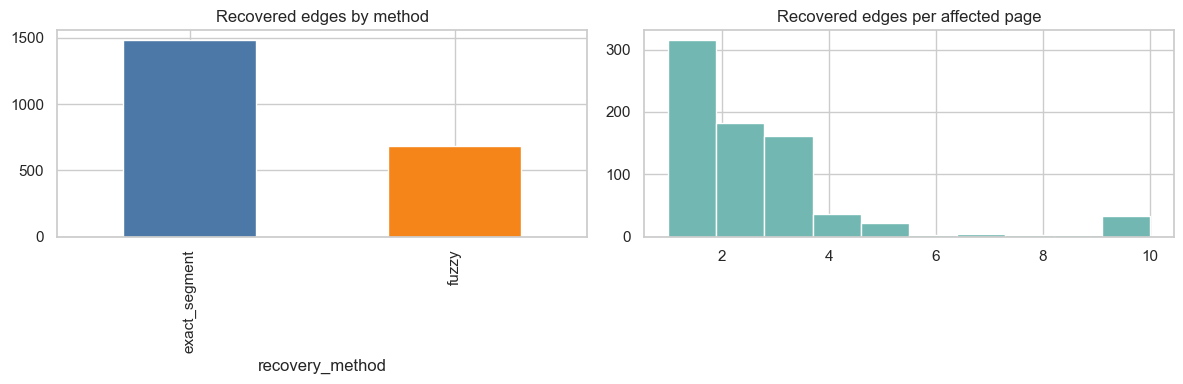

INSIGHT RECOVERY: using cached: /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick/reports/datathon_task2_v3_recovered_edges.csv; OCR engine is not rerun.


In [3]:
import re
from rapidfuzz import fuzz, process

def normalize_ocr_text(value):
    return re.sub(r'[^a-z0-9]+',' ',str(value).casefold()).strip()

# Prefer the persisted V3 result. This avoids repeating OCR-region recovery on
# every local run and also works when a previous output bundle is attached to Kaggle.
recovery_candidates = [LOCAL_PATRICK_PATH/'reports/datathon_task2_v3_recovered_edges.csv']
if IS_KAGGLE:
    recovery_candidates += list(Path('/kaggle/input').glob('**/datathon_task2_v3_recovered_edges.csv'))
RECOVERY_CACHE = next((p for p in recovery_candidates if p.exists()), None)

if RECOVERY_CACHE is not None:
    recovery = pd.read_csv(RECOVERY_CACHE)
    required = {'source_id','candidate_id','ocr_text','position_y','ocr_confidence','recovery_method'}
    assert required.issubset(recovery.columns), f'Recovery cache missing: {required-set(recovery.columns)}'
    recovery['match_score'] = recovery.get('match_score', 1.0)
    suspect_regions = raw_ocr.iloc[0:0].copy()
    recovery_source = f'cached: {RECOVERY_CACHE}'
else:
    title_map=articles.set_index('article_id').title.to_dict()
    normalized_titles={aid:normalize_ocr_text(title) for aid,title in title_map.items()}
    title_choices={aid:value for aid,value in normalized_titles.items() if len(value)>=4}
    candidate_title_len=raw_ocr.candidate_title.fillna('').astype(str).str.len()
    ocr_text_len=raw_ocr.ocr_text.fillna('').astype(str).str.len()
    suspect_regions=raw_ocr[(raw_ocr.status.ne('accepted'))|(ocr_text_len>candidate_title_len+3)].copy()
    recovery_rows=[]
    for row in suspect_regions.itertuples(index=False):
        text=normalize_ocr_text(row.ocr_text)
        if not text: continue
        padded=f' {text} '; found=set()
        for article_id,title_norm in title_choices.items():
            if f' {title_norm} ' in padded: found.add(int(article_id))
        method='exact_segment'
        if not found:
            method='fuzzy'
            for _,score,article_id in process.extract(text,title_choices,scorer=fuzz.WRatio,limit=3,score_cutoff=90):
                found.add(int(article_id))
            if text.startswith('l'):
                variant='i'+text[1:]
                for _,score,article_id in process.extract(variant,title_choices,scorer=fuzz.WRatio,limit=2,score_cutoff=94):
                    found.add(int(article_id))
        for article_id in found:
            if article_id==int(row.source_id): continue
            actual_method='exact_segment' if f' {normalized_titles[article_id]} ' in padded else method
            recovery_rows.append({'source_id':int(row.source_id),'candidate_id':article_id,'ocr_text':str(row.ocr_text),'position_y':float(row.position_y),'box_x':float(row.box_x),'ocr_confidence':float(row.ocr_confidence),'match_score':1.0,'recovery_method':actual_method})
    recovery=pd.DataFrame(recovery_rows).drop_duplicates(['source_id','candidate_id'])
    existing_edges=set(map(tuple,links[['source_id','candidate_id']].astype(int).to_numpy()))
    recovery=recovery[[tuple(x) not in existing_edges for x in recovery[['source_id','candidate_id']].to_numpy()]].reset_index(drop=True)
    recovery_source='computed fallback from raw OCR cache'

for column in links.columns:
    if column not in recovery.columns:
        recovery[column] = 1.0 if column == 'match_score' else 0.0
links_v3=pd.concat([links,recovery[links.columns]],ignore_index=True)
links_v3=links_v3.sort_values(['source_id','candidate_id','match_score','ocr_confidence'],ascending=[True,True,False,False]).drop_duplicates(['source_id','candidate_id']).reset_index(drop=True)
display(pd.Series({'recovery_source':recovery_source,'recovered_edges':len(recovery),'total_graph_edges':len(links_v3)}).to_frame('value'))
fig,ax=plt.subplots(1,2,figsize=(12,4))
recovery.recovery_method.value_counts().plot.bar(ax=ax[0],color=['#4c78a8','#f58518']); ax[0].set_title('Recovered edges by method')
recovery.groupby('source_id').size().clip(upper=10).hist(ax=ax[1],bins=10,color='#72b7b2'); ax[1].set_title('Recovered edges per affected page')
plt.tight_layout(); plt.show()
print(f'INSIGHT RECOVERY: using {recovery_source}; OCR engine is not rerun.')

## 4. Graph, OCR metadata, dan visual EDA

Graph recovered V3 tetap menjadi graph utama karena official full graph justru menurunkan diagnostic OOF.

In [4]:
n_articles = int(articles.article_id.max()) + 1
titles = articles.set_index('article_id').title.to_dict()
ocr_candidates = defaultdict(set)
for r in links_v3.itertuples(index=False):
    ocr_candidates[int(r.source_id)].add(int(r.candidate_id))

accepted_raw = raw_ocr[raw_ocr.status.eq('accepted') & raw_ocr.candidate_id.notna()].copy()
accepted_raw['candidate_id'] = accepted_raw.candidate_id.astype(int)
raw_agg = accepted_raw.groupby(['source_id','candidate_id']).agg(
    ocr_conf_max=('ocr_confidence','max'), ocr_conf_mean=('ocr_confidence','mean'),
    title_match_max=('match_score','max'), first_position=('position_y','min'),
    mention_count=('candidate_id','size')
).reset_index()
raw_meta = {
    (int(r.source_id),int(r.candidate_id)):(float(r.ocr_conf_max),float(r.ocr_conf_mean),float(r.title_match_max),float(r.first_position),int(r.mention_count))
    for r in raw_agg.itertuples(index=False)
}

for r in recovery.itertuples(index=False):
    raw_meta[(int(r.source_id),int(r.candidate_id))]=(float(r.ocr_confidence),float(r.ocr_confidence),1.0,float(r.position_y),1)

out_degree = np.zeros(n_articles,dtype=np.int32)
in_degree = np.zeros(n_articles,dtype=np.int32)
reverse_adj = [[] for _ in range(n_articles)]
incoming_sets = [set() for _ in range(n_articles)]
for source,candidates in ocr_candidates.items():
    out_degree[source] = len(candidates)
    for candidate in candidates:
        in_degree[candidate] += 1
        reverse_adj[candidate].append(source)
        incoming_sets[candidate].add(source)

graph_summary = pd.Series({
    'directed_edges':int(out_degree.sum()),
    'pages_with_links':int((out_degree>0).sum()),
    'pages_without_links':int((out_degree==0).sum()),
    'median_out_degree':float(np.median(out_degree[out_degree>0])),
    'p95_out_degree':float(np.percentile(out_degree[out_degree>0],95)),
})
display(graph_summary.to_frame('value'))

,value
directed_edges,95418.00
pages_with_links,4546.00
pages_without_links,58.00
median_out_degree,16.00
p95_out_degree,54.75


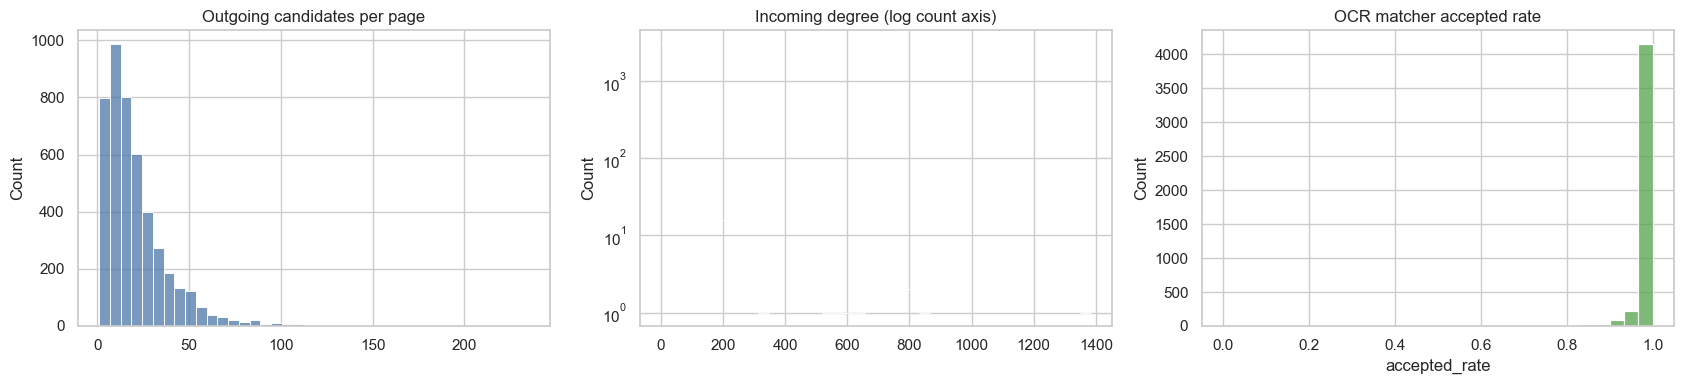

,source_id,regions,accepted_links,accepted_rate,mean_ocr_confidence,mean_match_score
1556,1577,1,0,0.000000,0.840000,0.000000
499,508,6,2,0.333333,0.934167,0.435307
273,277,7,3,0.428571,0.896429,0.642010
1827,1851,2,1,0.500000,0.960000,0.916667
1920,1945,2,1,0.500000,0.930000,0.500000
3162,3204,2,1,0.500000,0.947500,0.833333
3649,3695,2,1,0.500000,0.867500,0.500000
3892,3941,2,1,0.500000,0.957500,0.851351
3953,4002,8,4,0.500000,0.885042,0.683770
539,549,3,2,0.666667,0.956667,0.888889


INSIGHT GRAPH: candidate cap 100 mempertahankan hampir seluruh page, sedangkan long-tail degree mencegah pair table membesar tanpa batas.


In [5]:
fig, ax = plt.subplots(1,3,figsize=(17,4))
sns.histplot(out_degree[out_degree>0],bins=40,ax=ax[0],color='#4c78a8'); ax[0].set_title('Outgoing candidates per page')
sns.histplot(in_degree[in_degree>0],bins=40,ax=ax[1],color='#f58518',log_scale=(False,True)); ax[1].set_title('Incoming degree (log count axis)')
sns.histplot(quality.accepted_rate,bins=30,ax=ax[2],color='#54a24b'); ax[2].set_title('OCR matcher accepted rate')
plt.tight_layout(); plt.show()

low_quality = quality.sort_values(['accepted_rate','regions']).head(12)
display(low_quality)
print('INSIGHT GRAPH: candidate cap 100 mempertahankan hampir seluruh page, sedangkan long-tail degree mencegah pair table membesar tanpa batas.')

## 5. Competition-only semantic/category features dan reverse BFS

In [6]:
category_lists = categories.groupby('article_id').category.apply(list).to_dict()
category_sets = {i:set(category_lists.get(i,[])) for i in range(n_articles)}
category_tokens = {
    i:set(token.lower() for cat in category_lists.get(i,[]) for token in str(cat).replace('subject.','').replace('.',' ').replace('_',' ').split())
    for i in range(n_articles)
}
category_prefixes = {}
for aid in range(n_articles):
    prefixes=set()
    for category in category_lists.get(aid,[]):
        parts=str(category).split('.')
        prefixes.update('.'.join(parts[:depth]) for depth in range(2,len(parts)+1))
    category_prefixes[aid]=prefixes

docs=[]
for aid in range(n_articles):
    cat_doc=' '.join(str(x).replace('subject.',' ').replace('.',' ').replace('_',' ') for x in category_lists.get(aid,[]))
    docs.append(f'{titles[aid]} {titles[aid]} {cat_doc}')
word_x=TfidfVectorizer(ngram_range=(1,2),sublinear_tf=True).fit_transform(docs)
char_x=TfidfVectorizer(analyzer='char_wb',ngram_range=(2,5),min_df=2,sublinear_tf=True,max_features=30000).fit_transform(docs)
print('Word TF-IDF:',word_x.shape,'| Char TF-IDF:',char_x.shape)

Word TF-IDF: (4604, 17739) | Char TF-IDF: (4604, 17951)


In [7]:
dist_cache={}
def distances_to_target(target):
    target=int(target)
    if target in dist_cache: return dist_cache[target]
    dist=np.full(n_articles,99,dtype=np.int16); dist[target]=0
    queue=deque([target])
    while queue:
        node=queue.popleft(); nd=int(dist[node])+1
        for previous in reverse_adj[node]:
            if dist[previous]==99:
                dist[previous]=nd; queue.append(previous)
    dist_cache[target]=dist
    return dist

def sparse_cosine(matrix,candidates,target):
    return np.asarray(matrix[candidates].multiply(matrix[int(target)]).sum(axis=1)).ravel().astype(np.float32)

def jaccard(a,b):
    return len(a&b)/len(a|b) if (a or b) else 0.0

def fit_priors(frame):
    global_counts=Counter(frame.next_article_id.astype(int))
    current_counts=defaultdict(Counter)
    for r in frame.itertuples(index=False): current_counts[int(r.current_article_id)][int(r.next_article_id)]+=1
    return global_counts,current_counts,[x for x,_ in global_counts.most_common(30)]

## 6. Candidate-pair features dan grouped fold cache

In [8]:
FEATURES=[
 'direct_target','word_cosine','char_cosine','category_exact_jaccard','category_token_jaccard',
 'graph_distance','graph_improvement','on_shortest_path','is_min_neighbor_distance','distance_tie_count',
 'ocr_conf_max','ocr_conf_mean','title_match_max','first_position','log_mentions','log_global_clicks',
 'log_current_clicks','observed_edge','log_out_degree','log_in_degree','word_rank','char_rank','position_rank',
 'distance_rank','category_overlap_count','category_prefix_jaccard','out_neighbor_jaccard',
 'in_neighbor_jaccard','reciprocal_link'
]

def build_pairs(frame,priors,training=False):
    global_counts,current_counts,global_top=priors
    blocks=[]; labels=[]; states=[]; candidates_out=[]
    has_label='next_article_id' in frame.columns
    for row in frame.itertuples(index=False):
        state,current,target=int(row.state_id),int(row.current_article_id),int(row.target_article_id)
        truth=int(row.next_article_id) if has_label else None
        observed=set(current_counts.get(current,{}))
        candidates=set(ocr_candidates.get(current,set()))|observed
        if not candidates: candidates=set(global_top[:20])|{target}
        if training and truth is not None: candidates.add(truth)
        def priority(candidate):
            conf,_,match,position,mentions=raw_meta.get((current,candidate),(0,0,0,1,0))
            return candidate==truth,candidate==target,candidate in observed,match,conf,mentions,-position
        candidate_list=sorted(candidates,key=priority,reverse=True)[:MAX_CANDIDATES]
        cands=np.asarray(candidate_list,dtype=int)
        dist=distances_to_target(target); cdist=np.minimum(dist[cands].astype(np.float32),20)
        current_dist=min(int(dist[current]),20); min_dist=float(cdist.min()); tie_count=int((cdist==min_dist).sum())
        word=sparse_cosine(word_x,cands,target); char=sparse_cosine(char_x,cands,target)
        positions=np.asarray([raw_meta.get((current,int(c)),(0,0,0,1,0))[3] for c in cands],dtype=np.float32)
        block=np.zeros((len(cands),len(FEATURES)),dtype=np.float32)
        for idx,candidate in enumerate(cands):
            candidate=int(candidate); conf_max,conf_mean,match,position,mentions=raw_meta.get((current,candidate),(0,0,0,1,0))
            global_count=global_counts.get(candidate,0); current_count=current_counts.get(current,{}).get(candidate,0)
            if training and truth is not None and candidate==truth:
                global_count=max(0,global_count-1); current_count=max(0,current_count-1)
            block[idx,:20]=[
                candidate==target,word[idx],char[idx],jaccard(category_sets[candidate],category_sets[target]),
                jaccard(category_tokens[candidate],category_tokens[target]),cdist[idx],current_dist-cdist[idx],
                int(current_dist<20 and cdist[idx]+1==current_dist),cdist[idx]==min_dist,tie_count,
                conf_max,conf_mean,match,position,math.log1p(mentions),math.log1p(global_count),
                math.log1p(current_count),current_count>0,math.log1p(out_degree[candidate]),math.log1p(in_degree[candidate])]
            block[idx,24:]=[
                len(category_sets[candidate]&category_sets[target]),jaccard(category_prefixes[candidate],category_prefixes[target]),
                jaccard(ocr_candidates.get(candidate,set()),ocr_candidates.get(target,set())),
                jaccard(incoming_sets[candidate],incoming_sets[target]),candidate in ocr_candidates.get(target,set())]
        block[:,20]=pd.Series(word).rank(method='average',pct=True).to_numpy(np.float32)
        block[:,21]=pd.Series(char).rank(method='average',pct=True).to_numpy(np.float32)
        block[:,22]=pd.Series(-positions).rank(method='average',pct=True).to_numpy(np.float32)
        block[:,23]=pd.Series(-cdist).rank(method='average',pct=True).to_numpy(np.float32)
        blocks.append(block); labels.extend((cands==truth).astype(np.int8) if truth is not None else np.zeros(len(cands),dtype=np.int8))
        states.extend([state]*len(cands)); candidates_out.extend(cands.tolist())
    return np.vstack(blocks),np.asarray(labels,np.int8),np.asarray(states,np.int32),np.asarray(candidates_out,np.int32)

def evaluate_scores(y,states,candidates,scores):
    order=np.lexsort((candidates,-scores,states)); sorted_states=states[order]
    first=np.r_[True,sorted_states[1:]!=sorted_states[:-1]]; winners=order[first]
    ranked=pd.DataFrame({'state':states,'candidate':candidates,'truth':y,'score':scores}).sort_values(['state','score','candidate'],ascending=[True,False,True])
    ranked['rank']=ranked.groupby('state').cumcount()+1
    n_states=len(np.unique(states))
    return {
        'accuracy':float(y[winners].mean()),
        'top3':float(((ranked.truth==1)&(ranked['rank']<=3)).groupby(ranked.state).max().sum()/n_states),
        'top5':float(((ranked.truth==1)&(ranked['rank']<=5)).groupby(ranked.state).max().sum()/n_states),
        'candidate_recall':float(y.sum()/n_states),
    }

def winner_table(y,states,candidates,scores):
    order=np.lexsort((candidates,-scores,states)); sorted_states=states[order]
    first=np.r_[True,sorted_states[1:]!=sorted_states[:-1]]; idx=order[first]
    return pd.DataFrame({'state_id':states[idx],'prediction':candidates[idx],'correct':y[idx].astype(bool),'score':scores[idx]})

Fold 0: train pairs=128,296 | val pairs=64,363


Fold 1: train pairs=128,156 | val pairs=64,502


Fold 2: train pairs=128,886 | val pairs=63,757


,fold,candidate_recall,truth_is_min_distance,truth_is_unique_min,states_unique_min
0,0,0.994000,0.981000,0.273667,0.285000
1,1,0.994333,0.959667,0.261000,0.283333
2,2,0.993333,0.967333,0.255667,0.275333


,mean
fold,1.000000
candidate_recall,0.993889
truth_is_min_distance,0.969333
truth_is_unique_min,0.263444
states_unique_min,0.281222


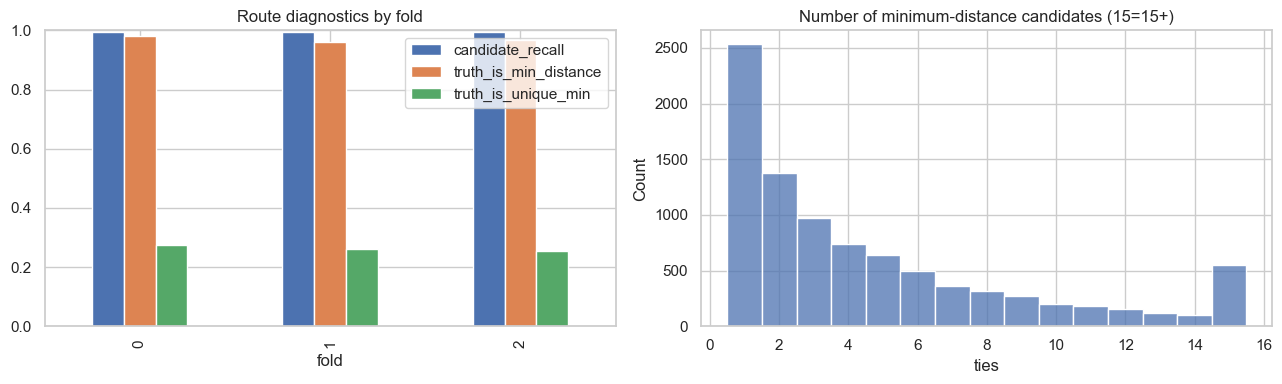

INSIGHT ROUTE: 96.93% truth berada di minimum distance, tetapi hanya 28.12% state memiliki minimum yang unik.


In [9]:
fold_cache=[]; route_rows=[]
splitter=GroupKFold(n_splits=N_SPLITS)
for fold,(fit_idx,val_idx) in enumerate(splitter.split(dev_train,groups=dev_train.target_article_id)):
    fit=dev_train.iloc[fit_idx].copy(); val=dev_train.iloc[val_idx].copy(); priors=fit_priors(fit)
    x_fit,y_fit,q_fit,c_fit=build_pairs(fit,priors,training=True)
    x_val,y_val,q_val,c_val=build_pairs(val,priors,training=False)
    state_count=len(np.unique(q_val)); positive=y_val==1
    tie_idx=FEATURES.index('distance_tie_count'); min_idx=FEATURES.index('is_min_neighbor_distance')
    state_ties=pd.DataFrame({'state':q_val,'ties':x_val[:,tie_idx]}).drop_duplicates('state')
    route_rows.append({
        'fold':fold,'candidate_recall':positive.sum()/state_count,
        'truth_is_min_distance':(positive&(x_val[:,min_idx]==1)).sum()/state_count,
        'truth_is_unique_min':(positive&(x_val[:,min_idx]==1)&(x_val[:,tie_idx]==1)).sum()/state_count,
        'states_unique_min':state_ties.ties.eq(1).mean(),
    })
    fold_cache.append({'fold':fold,'fit':(x_fit,y_fit,q_fit,c_fit),'val':(x_val,y_val,q_val,c_val)})
    print(f'Fold {fold}: train pairs={len(x_fit):,} | val pairs={len(x_val):,}')

route_df=pd.DataFrame(route_rows)
display(route_df); display(route_df.mean(numeric_only=True).to_frame('mean'))
fig,ax=plt.subplots(1,2,figsize=(13,4))
route_df.set_index('fold')[['candidate_recall','truth_is_min_distance','truth_is_unique_min']].plot.bar(ax=ax[0]); ax[0].set_ylim(0,1); ax[0].set_title('Route diagnostics by fold')
all_ties=pd.concat([pd.DataFrame({'state':f['val'][2],'ties':f['val'][0][:,FEATURES.index('distance_tie_count')]}) for f in fold_cache]).drop_duplicates('state')
sns.histplot(all_ties.ties.clip(upper=15),bins=15,discrete=True,ax=ax[1]); ax[1].set_title('Number of minimum-distance candidates (15=15+)')
plt.tight_layout(); plt.show()
print(f"INSIGHT ROUTE: {route_df.truth_is_min_distance.mean():.2%} truth berada di minimum distance, tetapi hanya {route_df.states_unique_min.mean():.2%} state memiliki minimum yang unik.")

## 7. Locked V4 shortest-path mass anchor

In [10]:
V3_HARDMIN = {
    'is_min_neighbor_distance':100.0,
    'category_exact_jaccard':1.51797340143258,
    'category_overlap_count':0.48994969864263294,
    'category_prefix_jaccard':0.02857276307887291,
    'log_global_clicks':0.02119646682476861,
    'log_in_degree':0.4340986164482358,
    'out_neighbor_jaccard':0.9794117699297289,
    'in_neighbor_jaccard':0.2994440985929203,
    'char_cosine':0.35850562724901813,
    'word_cosine':0.1653051475375229,
    'position_rank':0.04515262127215465,
}
V3_FEATURES=list(V3_HARDMIN)
V3_WEIGHTS=np.asarray([V3_HARDMIN[x] for x in V3_FEATURES],np.float32)
path_count_cache={}
def log_shortest_path_count_to_target(target):
    target=int(target)
    if target in path_count_cache: return path_count_cache[target]
    dist=distances_to_target(target); finite=dist<99
    counts=np.zeros(n_articles,dtype=np.float64); counts[target]=1.0
    max_distance=int(dist[finite].max()) if finite.any() else 0
    for depth in range(1,max_distance+1):
        for node in np.flatnonzero(dist==depth):
            children=np.fromiter(ocr_candidates.get(int(node),()),dtype=np.int32)
            if children.size:
                shortest=children[dist[children]==depth-1]
                if shortest.size: counts[node]=min(1e12,counts[shortest].sum())
    result=np.log1p(counts).astype(np.float32)
    path_count_cache[target]=result
    return result

state_target=train.set_index('state_id').target_article_id.to_dict()
def path_feature_for_pairs(qids,candidates,target_lookup=state_target):
    result=np.zeros(len(qids),dtype=np.float32)
    state_frame=pd.DataFrame({'row':np.arange(len(qids)),'state_id':qids.astype(int),'candidate':candidates.astype(int)})
    state_frame['target']=state_frame.state_id.map(target_lookup).astype(int)
    for target,group in state_frame.groupby('target',sort=False):
        result[group.row.to_numpy()]=log_shortest_path_count_to_target(int(target))[group.candidate.to_numpy(int)]
    return result

display(pd.Series({'locked_v3_features':len(V3_FEATURES),'cached_targets_initially':len(path_count_cache),'path_count_cap':1e12}).to_frame('value'))
print('INSIGHT FEATURE: path mass hanya membedakan route structure; minimum-distance constraint V3 tetap dominan.')

,value
locked_v3_features,1.100000e+01
cached_targets_initially,0.000000e+00
path_count_cap,1.000000e+12


INSIGHT FEATURE: path mass hanya membedakan route structure; minimum-distance constraint V3 tetap dominan.


## 8. Research findings yang membentuk V5

Dataset cocok dengan statistik Wikispeedia: 4.604 artikel dan sekitar 120 ribu links. Studi human wayfinding menemukan strategi **zoom-out** menuju high-degree hubs pada fase awal dan **homing-in** berbasis content similarity pada fase akhir. Studi article structure juga menemukan bias ke lead/infobox dan link di bagian atas halaman.

Diagnostic lokal V5 menguji semua implikasi tersebut:

- MiniLM cosine tunggal: tidak stabil;
- surrounding-context MiniLM: hanya 50,97% memilih truth pada V4 errors;
- phase-aware degree/semantic/layout: tidak mengalahkan nested V4;
- official Wikispeedia graph: hanya 69,09%, sehingga tidak dipakai;
- external navigation paths: tidak dimuat di notebook ini.

Yang bertahan adalah nonlinear embedding interaction: model dapat mempelajari dimensi hubungan candidate–target yang hilang ketika 384 dimensi dipadatkan menjadi satu cosine.

Referensi: [Human Wayfinding in Information Networks](https://ai.stanford.edu/~jure/pubs/wayfinding-www12.pdf), [article-structure navigation study](https://pmc.ncbi.nlm.nih.gov/articles/PMC5468769/), dan [official SNAP Wikispeedia description](https://snap.stanford.edu/data/wikispeedia.html).

## 9. Load cached MiniLM article embeddings

Cache berisi satu normalized 384-D vector per article. Encoding tidak diulang dalam notebook.

In [11]:
EMBEDDING_NAME='datathon_task2_v5_minilm_article_embeddings.npz'
embedding_candidates=[OUTPUT_DIR/EMBEDDING_NAME,LOCAL_PATRICK_PATH/'output/v5'/EMBEDDING_NAME]
if IS_KAGGLE:
    embedding_candidates += list(Path('/kaggle/input').glob(f'**/{EMBEDDING_NAME}'))
EMBEDDING_PATH=next((p for p in embedding_candidates if p.exists()),None)
if EMBEDDING_PATH is None:
    raise FileNotFoundError(f'Attach V5 reusable bundle containing {EMBEDDING_NAME}. No model download is required when cache is attached.')
article_embedding=np.load(EMBEDDING_PATH)['embeddings'].astype(np.float32)
assert article_embedding.shape==(n_articles,384)
article_embedding/=np.maximum(np.linalg.norm(article_embedding,axis=1,keepdims=True),1e-8)
from sklearn.decomposition import PCA
pca=PCA(n_components=48,whiten=True,random_state=SEED)
embedding_pca=pca.fit_transform(article_embedding).astype(np.float32)
embedding_pca/=np.maximum(np.linalg.norm(embedding_pca,axis=1,keepdims=True),1e-8)
display(pd.Series({'embedding_path':str(EMBEDDING_PATH),'articles':len(article_embedding),'original_dimensions':384,'pair_ranker_dimensions':48,'pca_explained_variance':pca.explained_variance_ratio_.sum()}).to_frame('value'))
print('INSIGHT CACHE: pretrained encoder inference is skipped; only cached vectors and CPU PCA are used.')

,value
embedding_path,/Users/timotiuspatrick/Documents/Patrick/Kulia...
articles,4604
original_dimensions,384
pair_ranker_dimensions,48
pca_explained_variance,0.674197


INSIGHT CACHE: pretrained encoder inference is skipped; only cached vectors and CPU PCA are used.


## 10. Pairwise embedding interactions

For each `(current, candidate, target)` pair, V5 builds:

- candidate × target elementwise product;
- absolute candidate–target difference;
- candidate and target PCA coordinates;
- directional progress from current toward target;
- V4 graph/category/layout features.

Training is restricted to minimum-distance candidates whose truth is present. Every query contributes equal positive and negative mass.

In [12]:
TABULAR=['word_cosine','char_cosine','category_exact_jaccard','category_token_jaccard','log_global_clicks','log_current_clicks','log_in_degree','log_out_degree','word_rank','char_rank','position_rank','category_overlap_count','category_prefix_jaccard','out_neighbor_jaccard','in_neighbor_jaccard','reciprocal_link']
TABULAR_INDEX=[FEATURES.index(name) for name in TABULAR]
MIN_INDEX=FEATURES.index('is_min_neighbor_distance')
TRAIN_LOOKUP=train.set_index('state_id')[['current_article_id','target_article_id']]
TEST_LOOKUP=test.set_index('state_id')[['current_article_id','target_article_id']]
def pair_embedding_features(qids,candidates,lookup):
    frame=pd.DataFrame({'state_id':qids.astype(int),'candidate':candidates.astype(int)}).join(lookup,on='state_id')
    candidate=embedding_pca[frame.candidate.to_numpy(int)]; target=embedding_pca[frame.target_article_id.to_numpy(int)]; current=embedding_pca[frame.current_article_id.to_numpy(int)]
    product=candidate*target; absolute=np.abs(candidate-target); direction=candidate-current; target_direction=target-current
    scalar=np.column_stack([np.sum(candidate*target,axis=1),np.sum(candidate*current,axis=1),np.sum(current*target,axis=1),np.sum(direction*target_direction,axis=1),np.linalg.norm(target_direction,axis=1)-np.linalg.norm(target-candidate,axis=1)]).astype(np.float32)
    return np.column_stack([product,absolute,candidate,target,scalar]).astype(np.float32)
def query_rank(values,qids):
    return pd.DataFrame({'value':values,'qid':qids}).groupby('qid').value.rank(pct=True,method='average').to_numpy(np.float32)
PARAMS=[
 {'num_leaves':7,'min_child_samples':30,'reg_lambda':8.0},
 {'num_leaves':15,'min_child_samples':30,'reg_lambda':10.0},
 {'num_leaves':15,'min_child_samples':60,'reg_lambda':15.0},
 {'num_leaves':31,'min_child_samples':50,'reg_lambda':20.0},
]
BETAS=[0.0,.05,.1,.2,.3,.5,.8,1.2,2.0]
LOCKED_CONFIG=3; LOCKED_BETA=0.30

## 11. Grouped OOF training dan blend search

MiniLM is frozen. Only lightweight LightGBM classifiers are trained on CPU.

In [13]:
import lightgbm as lgb
predictions=[]; fold_models=[]
for cache in fold_cache:
    fold=cache['fold']; x_fit,y_fit,q_fit,c_fit=cache['fit']; x_val,y_val,q_val,c_val=cache['val']
    fit_min=x_fit[:,MIN_INDEX]==1; valid_queries=np.unique(q_fit[fit_min&(y_fit==1)]); fit_mask=fit_min&np.isin(q_fit,valid_queries)
    fit_path=path_feature_for_pairs(q_fit,c_fit); val_path=path_feature_for_pairs(q_val,c_val)
    x_train=np.column_stack([x_fit[fit_mask][:,TABULAR_INDEX],fit_path[fit_mask],pair_embedding_features(q_fit[fit_mask],c_fit[fit_mask],TRAIN_LOOKUP)])
    x_valid=np.column_stack([x_val[:,TABULAR_INDEX],val_path,pair_embedding_features(q_val,c_val,TRAIN_LOOKUP)])
    y_train=y_fit[fit_mask]; q_train=q_fit[fit_mask]; sizes=pd.Series(q_train).value_counts().to_dict()
    weights=np.asarray([.5 if label==1 else .5/max(1,sizes[int(qid)]-1) for label,qid in zip(y_train,q_train)],np.float32)
    anchor=x_val[:,[FEATURES.index(name) for name in V3_FEATURES]]@V3_WEIGHTS+.20*val_path
    for config_id,params in enumerate(PARAMS):
        model=lgb.LGBMClassifier(objective='binary',n_estimators=300,learning_rate=.025,colsample_bytree=.75,subsample=.9,random_state=SEED+fold,verbosity=-1,n_jobs=-1,**params)
        model.fit(x_train,y_train,sample_weight=weights)
        probability=model.predict_proba(x_valid)[:,1].astype(np.float32)
        predictions.append({'fold':fold,'config_id':config_id,'y':y_val,'q':q_val,'c':c_val,'x':x_val,'anchor':anchor,'probability':probability,'rank':query_rank(probability,q_val)})
        if config_id==LOCKED_CONFIG: fold_models.append(model)
    print(f'Fold {fold}: train={len(x_train):,} minimum-distance pairs | validation={len(x_valid):,} all pairs')
search_rows=[]
for item in predictions:
    for signal in ['probability','rank']:
        for beta in BETAS:
            search_rows.append({'fold':item['fold'],'config_id':item['config_id'],'signal':signal,'beta':beta,**evaluate_scores(item['y'],item['q'],item['c'],item['anchor']+beta*item[signal])})
search=pd.DataFrame(search_rows)
summary=search.groupby(['config_id','signal','beta'],as_index=False).agg(mean_accuracy=('accuracy','mean'),std_accuracy=('accuracy','std'),top3=('top3','mean'),top5=('top5','mean')).sort_values(['mean_accuracy','std_accuracy'],ascending=[False,True])
display(summary.head(15))

Fold 0: train=29,819 minimum-distance pairs | validation=64,363 all pairs


Fold 1: train=29,862 minimum-distance pairs | validation=64,502 all pairs


Fold 2: train=29,322 minimum-distance pairs | validation=63,757 all pairs


,config_id,signal,beta,mean_accuracy,std_accuracy,top3,top5
57,3,probability,0.20,0.774889,0.018584,0.943556,0.974111
58,3,probability,0.30,0.774889,0.019097,0.943111,0.974222
56,3,probability,0.10,0.774778,0.018845,0.944222,0.974000
10,0,rank,0.05,0.774667,0.019539,0.944556,0.974111
38,2,probability,0.10,0.774667,0.019616,0.944444,0.974111
2,0,probability,0.10,0.774667,0.020033,0.944667,0.974000
11,0,rank,0.10,0.774667,0.020915,0.943889,0.973667
65,3,rank,0.10,0.774556,0.019845,0.943333,0.974000
19,1,probability,0.05,0.774333,0.019140,0.944444,0.974000
64,3,rank,0.05,0.774333,0.019376,0.944444,0.974111


## 12. Nested stability dan V4 comparison

fold,0,1,2
model,,,
V4 anchor,0.796000,0.756667,0.768
V5 semantic pair blend,0.796667,0.761000,0.767


,fold,accuracy,top3,top5,candidate_recall
model,,,,,
V4 anchor,1.0,0.773556,0.944333,0.974111,0.993889
V5 semantic pair blend,1.0,0.774889,0.943111,0.974222,0.993889


,held_fold,config_id,signal,beta,selection_accuracy,held_accuracy
0,0,3,probability,0.2,0.764333,0.796000
1,1,0,rank,0.1,0.782667,0.758667
2,2,3,probability,0.3,0.778833,0.767000


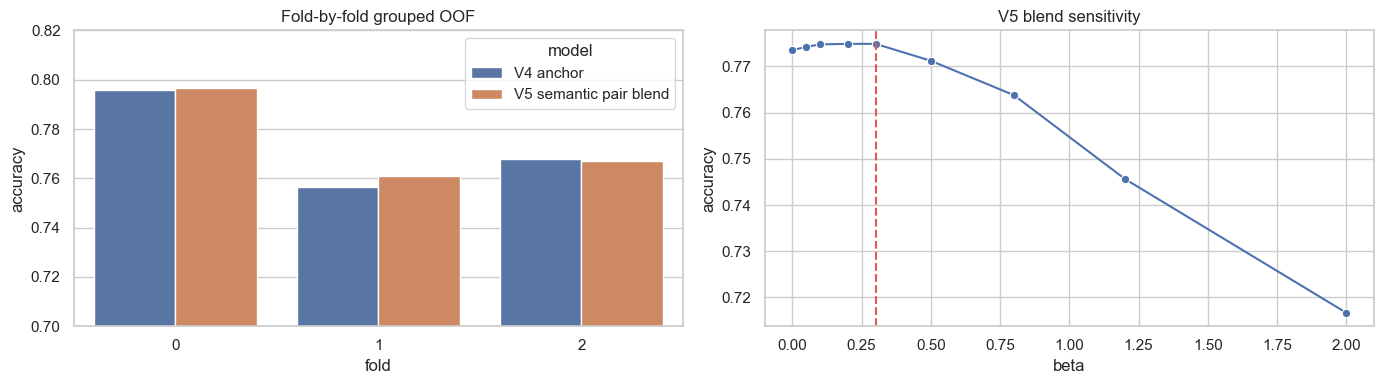

Nested mean: 77.3889%


In [14]:
nested_rows=[]
for held_fold in range(N_SPLITS):
    selection=search[search.fold.ne(held_fold)].groupby(['config_id','signal','beta']).accuracy.mean().sort_values(ascending=False)
    config_id,signal,beta=selection.index[0]
    held=search[(search.fold.eq(held_fold))&(search.config_id.eq(config_id))&(search.signal.eq(signal))&(search.beta.eq(beta))].iloc[0]
    nested_rows.append({'held_fold':held_fold,'config_id':int(config_id),'signal':signal,'beta':float(beta),'selection_accuracy':selection.iloc[0],'held_accuracy':held.accuracy})
nested=pd.DataFrame(nested_rows)
comparison_rows=[]; oof_v5=[]; change_rows=[]
for item in [x for x in predictions if x['config_id']==LOCKED_CONFIG]:
    v4=item['anchor']; v5=v4+LOCKED_BETA*item['probability']
    comparison_rows += [{'fold':item['fold'],'model':'V4 anchor',**evaluate_scores(item['y'],item['q'],item['c'],v4)},{'fold':item['fold'],'model':'V5 semantic pair blend',**evaluate_scores(item['y'],item['q'],item['c'],v5)}]
    v4_w=winner_table(item['y'],item['q'],item['c'],v4).rename(columns={'prediction':'v4_prediction','correct':'v4_correct','score':'v4_score'})
    v5_w=winner_table(item['y'],item['q'],item['c'],v5).rename(columns={'prediction':'v5_prediction','correct':'v5_correct','score':'v5_score'})
    merged=v4_w.merge(v5_w,on='state_id'); merged['fold']=item['fold']; oof_v5.append(merged)
selected_cv=pd.DataFrame(comparison_rows)
display(selected_cv.pivot(index='model',columns='fold',values='accuracy')); display(selected_cv.groupby('model').mean(numeric_only=True)); display(nested)
fig,ax=plt.subplots(1,2,figsize=(14,4)); sns.barplot(data=selected_cv,x='fold',y='accuracy',hue='model',ax=ax[0]); ax[0].set_ylim(.70,.82); ax[0].set_title('Fold-by-fold grouped OOF')
beta_curve=search[search.config_id.eq(LOCKED_CONFIG)&search.signal.eq('probability')].groupby('beta').accuracy.mean().reset_index(); sns.lineplot(data=beta_curve,x='beta',y='accuracy',marker='o',ax=ax[1]); ax[1].axvline(LOCKED_BETA,color='#e45756',ls='--'); ax[1].set_title('V5 blend sensitivity'); plt.tight_layout(); plt.show()
print(f'Nested mean: {nested.held_accuracy.mean():.4%}')

## 13. Error-level reverse engineering

Changed predictions, fixes, regressions, and remaining taxonomy are persisted for V6.

,states
changed,199
fixed,85
regressed,73
both_wrong,41
net_correct,12


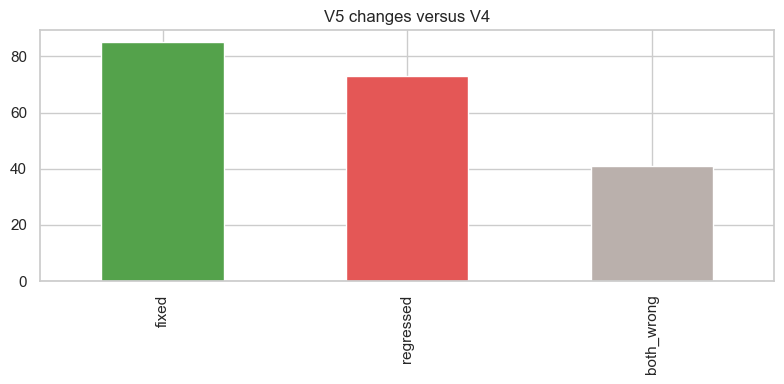

INSIGHT ERROR: only a small semantic correction is trusted; shortest-path anchor remains dominant.


In [15]:
oof=pd.concat(oof_v5,ignore_index=True).merge(train[['state_id','current_article_id','target_article_id','next_article_id']],on='state_id',how='left')
oof['changed']=oof.v4_prediction.ne(oof.v5_prediction); oof['fixed']=oof.changed&~oof.v4_correct&oof.v5_correct; oof['regressed']=oof.changed&oof.v4_correct&~oof.v5_correct
change_summary=pd.Series({'changed':oof.changed.sum(),'fixed':oof.fixed.sum(),'regressed':oof.regressed.sum(),'both_wrong':(oof.changed&~oof.v4_correct&~oof.v5_correct).sum(),'net_correct':oof.v5_correct.sum()-oof.v4_correct.sum()})
display(change_summary.to_frame('states'))
fig,ax=plt.subplots(figsize=(8,4)); change_summary[['fixed','regressed','both_wrong']].plot.bar(ax=ax,color=['#54a24b','#e45756','#bab0ac']); ax.set_title('V5 changes versus V4'); plt.tight_layout(); plt.show()
print('INSIGHT ERROR: only a small semantic correction is trusted; shortest-path anchor remains dominant.')

## 14. Train full model dan test inference

In [16]:
full_priors=fit_priors(train)
x_full,y_full,q_full,c_full=build_pairs(train,full_priors,training=True)
x_test,_,q_test,c_test=build_pairs(test,full_priors,training=False)
full_min=x_full[:,MIN_INDEX]==1; valid_full=np.unique(q_full[full_min&(y_full==1)]); full_mask=full_min&np.isin(q_full,valid_full)
full_path=path_feature_for_pairs(q_full,c_full); test_target=test.set_index('state_id').target_article_id.to_dict(); test_path=path_feature_for_pairs(q_test,c_test,test_target)
x_train_full=np.column_stack([x_full[full_mask][:,TABULAR_INDEX],full_path[full_mask],pair_embedding_features(q_full[full_mask],c_full[full_mask],TRAIN_LOOKUP)])
x_test_model=np.column_stack([x_test[:,TABULAR_INDEX],test_path,pair_embedding_features(q_test,c_test,TEST_LOOKUP)])
y_train_full=y_full[full_mask]; q_train_full=q_full[full_mask]; full_sizes=pd.Series(q_train_full).value_counts().to_dict()
full_weights=np.asarray([.5 if label==1 else .5/max(1,full_sizes[int(qid)]-1) for label,qid in zip(y_train_full,q_train_full)],np.float32)
final_model=lgb.LGBMClassifier(objective='binary',n_estimators=300,learning_rate=.025,colsample_bytree=.75,subsample=.9,random_state=SEED,verbosity=-1,n_jobs=-1,**PARAMS[LOCKED_CONFIG])
final_model.fit(x_train_full,y_train_full,sample_weight=full_weights)
test_probability=final_model.predict_proba(x_test_model)[:,1].astype(np.float32)
v4_test=x_test[:,[FEATURES.index(name) for name in V3_FEATURES]]@V3_WEIGHTS+.20*test_path
v5_test=v4_test+LOCKED_BETA*test_probability
v5_winners=winner_table(np.zeros(len(q_test),np.int8),q_test,c_test,v5_test); v4_winners=winner_table(np.zeros(len(q_test),np.int8),q_test,c_test,v4_test)
v5_prediction=v5_winners.set_index('state_id').prediction.astype(int); v4_prediction=v4_winners.set_index('state_id').prediction.astype(int)
primary=sample[['state_id']].copy(); primary['predicted_next_article_id']=primary.state_id.map(v5_prediction).astype(int)
fallback=sample[['state_id']].copy(); fallback['predicted_next_article_id']=fallback.state_id.map(v4_prediction).astype(int)
print('V5 vs V4 test disagreement:',(primary.predicted_next_article_id!=fallback.predicted_next_article_id).mean()); display(primary.head())

V5 vs V4 test disagreement: 0.027333333333333334


,state_id,predicted_next_article_id
0,0,4393
1,6,315
2,8,237
3,10,1689
4,11,4503


## 15. Audit, submission, dan reusable artifacts

In [17]:
valid_ids=set(articles.article_id.astype(int))
def audit_submission(frame):
    return {'rows':len(frame),'unique_states':frame.state_id.nunique(),'nan':int(frame.predicted_next_article_id.isna().sum()),'invalid_article_ids':int((~frame.predicted_next_article_id.isin(valid_ids)).sum()),'same_as_current':float((frame.predicted_next_article_id.to_numpy()==test.current_article_id.to_numpy()).mean()),'same_as_target':float((frame.predicted_next_article_id.to_numpy()==test.target_article_id.to_numpy()).mean()),'unique_predictions':frame.predicted_next_article_id.nunique()}
primary_audit=audit_submission(primary); fallback_audit=audit_submission(fallback)
assert primary_audit['rows']==6000 and primary_audit['unique_states']==6000 and primary_audit['nan']==0 and primary_audit['invalid_article_ids']==0
primary_path=OUTPUT_DIR/'datathon_task2_v5_semantic_pair_blend_beta030.csv'; fallback_path=OUTPUT_DIR/'datathon_task2_v5_v4_fallback.csv'
primary.to_csv(primary_path,index=False); fallback.to_csv(fallback_path,index=False)
selected_cv.to_csv(OUTPUT_DIR/'datathon_task2_v5_cv.csv',index=False); search.to_csv(OUTPUT_DIR/'datathon_task2_v5_blend_search.csv',index=False); nested.to_csv(OUTPUT_DIR/'datathon_task2_v5_nested.csv',index=False); oof.to_csv(OUTPUT_DIR/'datathon_task2_v5_oof_error_pack.csv',index=False)
joblib.dump({'model':final_model,'pca':pca,'tabular':TABULAR,'params':PARAMS[LOCKED_CONFIG],'beta':LOCKED_BETA},OUTPUT_DIR/'datathon_task2_v5_semantic_pair_ranker.joblib')
diagnostics={'version':'v5_pretrained_semantic_pair_ranker','seed':SEED,'embedding_path':str(EMBEDDING_PATH),'locked_config':LOCKED_CONFIG,'locked_beta':LOCKED_BETA,'runtime_minutes':(time.time()-START_TIME)/60,'selected_cv':selected_cv.groupby('model').mean(numeric_only=True).to_dict('index'),'nested_accuracy':nested.held_accuracy.mean(),'changes':change_summary.to_dict(),'primary_audit':primary_audit,'fallback_audit':fallback_audit,'test_disagreement':float((primary.predicted_next_article_id!=fallback.predicted_next_article_id).mean())}
(OUTPUT_DIR/'datathon_task2_v5_diagnostics.json').write_text(json.dumps(diagnostics,indent=2))
archive=shutil.make_archive(str(OUTPUT_DIR.parent/'datathon_task2_v5_beta030_artifacts'),'zip',OUTPUT_DIR)
display(pd.DataFrame({'primary_v5':primary_audit,'fallback_v4':fallback_audit})); print('Primary:',primary_path); print('Bundle:',archive); print(f'Total runtime: {(time.time()-START_TIME)/60:.2f} minutes')

,primary_v5,fallback_v4
rows,6000.000000,6000.000000
unique_states,6000.000000,6000.000000
nan,0.000000,0.000000
invalid_article_ids,0.000000,0.000000
same_as_current,0.000000,0.000000
same_as_target,0.007333,0.007333
unique_predictions,784.000000,780.000000


Primary: /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick/output/v5_beta030/datathon_task2_v5_semantic_pair_blend_beta030.csv
Bundle: /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick/output/datathon_task2_v5_beta030_artifacts.zip
Total runtime: 1.09 minutes


## Keputusan setelah run

- Primary V5: `datathon_task2_v5_semantic_pair_blend.csv` bila grouped dan nested OOF melampaui V4.
- V4 fallback tetap diekspor karena expected gain V5 kecil.
- Upload `datathon_task2_v5_artifacts.zip` sebagai Kaggle Dataset untuk reuse embedding tanpa download/model inference.
- External Wikispeedia navigation ground truth tidak digunakan oleh notebook atau submission.